# Question 7: Forecast August 2026 activity

County-level forecasts for households (the visits proxy), pounds and individuals, plus the graduate addendum forecasts for children, adults and seniors. The reproducible forecasting logic lives in `questions/q7_forecast_august/analysis.py`; this notebook runs it and explores its diagnostics and results.

> **Hard cutoff:** August 2026 data from any source is prohibited. The only permissible forecast input ends in July 2026. Do not search for or load August 2026 actuals.

## Setup and leakage guard

The notebook locates the repository root from the current directory, loads the canonical processed county-month panel, checks the hard cutoff, and then runs the same script used to generate the saved tables. Backtests use August 2023, 2024 and 2025, each using only observations strictly before its target month.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src" / "qkit.py").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate repository root containing src/qkit.py")

sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import config as cfg
import qkit

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print(f"Repository: {ROOT}")
print(f"Permitted training cutoff: {cfg.TRAIN_CUTOFF_YM}")
print(f"Forecast target (not observed): {cfg.FORECAST_TARGET_YM}")

Repository: /Users/uddam/Desktop/MinneMUDAC
Permitted training cutoff: 202607
Forecast target (not observed): 202608


In [2]:
panel = qkit.county_month()
qkit.leakage_check(panel)
panel = panel.loc[panel["yearmonth"].le(cfg.TRAIN_CUTOFF_YM)].copy()
if panel["yearmonth"].max() != cfg.TRAIN_CUTOFF_YM:
    raise ValueError("Expected the permitted panel to end in July 2026")

display(pd.DataFrame({
    "rows": [len(panel)],
    "counties_with_reporting_history": [panel["fips"].nunique()],
    "months": [panel["yearmonth"].nunique()],
    "first_month": [panel["yearmonth"].min()],
    "last_permitted_month": [panel["yearmonth"].max()],
    "July 2026 reporting sites (statewide sum)": [panel.loc[panel.yearmonth.eq(cfg.TRAIN_CUTOFF_YM), "n_sites_reporting"].sum()],
}))

leakage_check passed: nothing at or after 202608


,rows,counties_with_reporting_history,months,first_month,last_permitted_month,July 2026 reporting sites (statewide sum)
0,4730,86,55,202201,202607,488


## Exploratory analysis: understand the panel before forecasting

Start by checking the panel's coverage and reporting completeness, then inspect statewide trends and county-level August/July variation. These are descriptive checks—not forecasts—and all calculations use the cutoff-filtered `panel` created above. No data from August 2026 or later is used.

In [3]:
metrics = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]

coverage = pd.DataFrame({
    "rows": [len(panel)],
    "distinct_counties": [panel.fips.nunique()],
    "distinct_months": [panel.yearmonth.nunique()],
    "missing_county_months_vs_87_counties": [87 * panel.yearmonth.nunique() - len(panel)],
    "first_yearmonth": [panel.yearmonth.min()],
    "last_yearmonth": [panel.yearmonth.max()],
})
quality = pd.DataFrame({
    "missing_values": panel[metrics + ["n_sites_reporting"]].isna().sum(),
    "zero_values": panel[metrics + ["n_sites_reporting"]].eq(0).sum(),
    "minimum": panel[metrics + ["n_sites_reporting"]].min(),
})
display(coverage)
display(quality)

# Counties absent from the activity panel are reporting gaps, not observed zeroes.
reference = qkit.mmg(years=[2024])[['fips', 'county_name']].drop_duplicates()
reference['fips'] = reference.fips.astype('string').str.zfill(5)
observed_fips = set(panel.fips.astype('string').str.zfill(5))
no_activity = reference.loc[~reference.fips.isin(observed_fips)]
display(no_activity)

,rows,distinct_counties,distinct_months,missing_county_months_vs_87_counties,first_yearmonth,last_yearmonth
0,4730,86,55,55,202201,202607


,missing_values,zero_values,minimum
households,0,10,0.0
pounds,0,10,0.0
individuals,0,9,0.0
children,0,9,0.0
adults,0,9,0.0
seniors,0,9,0.0
n_sites_reporting,0,0,1.0


,fips,county_name
518,27167,Wilkin


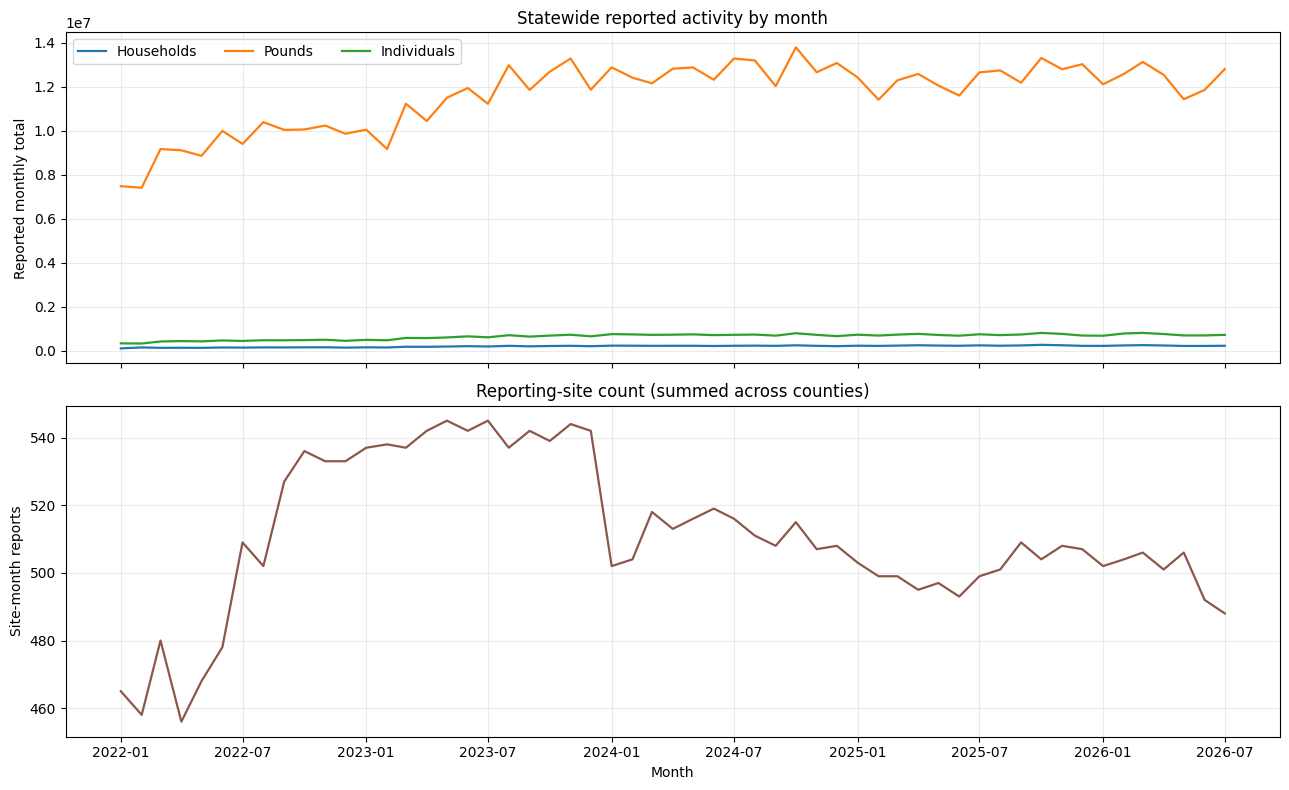

July 2026 reporting sites: 488; previous 11-month average: 503.6; difference: -3.1%


In [4]:
# Statewide totals by month, using county-month observations through July 2026 only.
state_monthly = (panel.groupby(["yearmonth", "date"], as_index=False)[metrics + ["n_sites_reporting"]]
                 .sum().sort_values("yearmonth"))
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for metric in cfg.THREE_METRICS:
    axes[0].plot(state_monthly.date, state_monthly[metric], label=metric.title(), linewidth=1.6)
axes[0].set(title="Statewide reported activity by month", ylabel="Reported monthly total")
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.25)
axes[1].plot(state_monthly.date, state_monthly.n_sites_reporting, color="#8c564b", linewidth=1.6)
axes[1].set(title="Reporting-site count (summed across counties)", ylabel="Site-month reports", xlabel="Month")
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

# Compare the final permitted month with recent reporting-site history.
latest_sites = state_monthly.loc[state_monthly.yearmonth.eq(cfg.TRAIN_CUTOFF_YM), "n_sites_reporting"].iloc[0]
trailing_sites = state_monthly.loc[state_monthly.yearmonth.between(202508, 202606), "n_sites_reporting"].mean()
print(f"July 2026 reporting sites: {latest_sites:,.0f}; previous 11-month average: {trailing_sites:,.1f}; difference: {100 * (latest_sites / trailing_sites - 1):+.1f}%")

,year,metric,counties,median_ratio,q10_ratio,q90_ratio
0,2022,households,86,1.051,0.826,1.215
1,2022,pounds,86,1.072,0.818,1.292
2,2022,individuals,86,1.035,0.823,1.151
6,2023,households,86,1.075,0.916,1.260
7,2023,pounds,86,1.145,0.974,1.320
8,2023,individuals,86,1.072,0.926,1.321
12,2024,households,85,0.985,0.850,1.184
13,2024,pounds,85,0.985,0.830,1.195
14,2024,individuals,85,0.956,0.748,1.153
18,2025,households,86,0.930,0.815,1.114


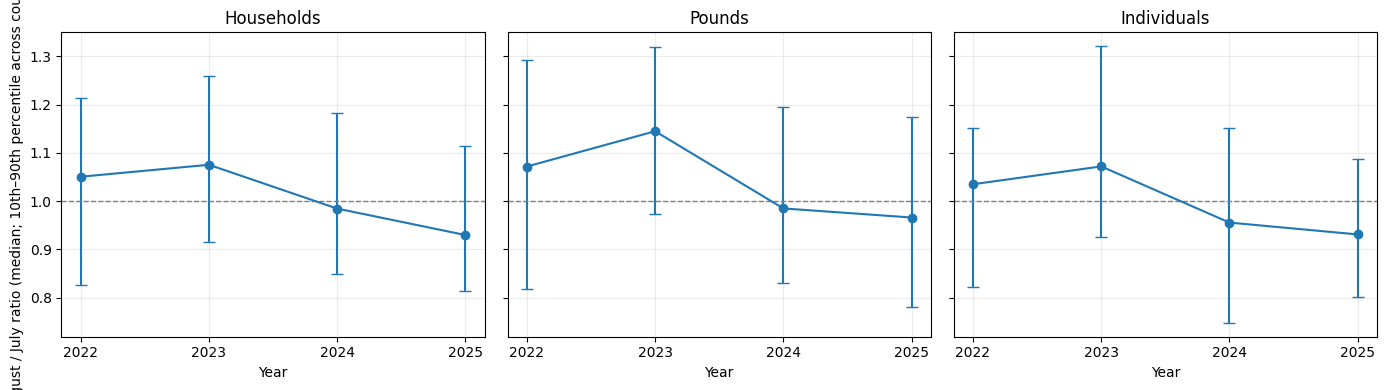

In [5]:
# County-level August/July ratios vary substantially; summarize by metric and year.
ratio_rows = []
for year in range(2022, 2026):
    july = panel.loc[panel.yearmonth.eq(year * 100 + 7), ["fips", *metrics]].set_index("fips")
    august = panel.loc[panel.yearmonth.eq(year * 100 + 8), ["fips", *metrics]].set_index("fips")
    ratios = august.div(july.where(july.gt(0))).replace([np.inf, -np.inf], np.nan)
    for metric in metrics:
        values = ratios[metric].dropna()
        ratio_rows.append({
            "year": year, "metric": metric, "counties": len(values),
            "median_ratio": values.median(),
            "q10_ratio": values.quantile(0.10),
            "q90_ratio": values.quantile(0.90),
        })
ratio_summary = pd.DataFrame(ratio_rows)
display(ratio_summary.loc[ratio_summary.metric.isin(cfg.THREE_METRICS)].round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, metric in zip(axes, cfg.THREE_METRICS):
    subset = ratio_summary.loc[ratio_summary.metric.eq(metric)]
    ax.errorbar(subset.year, subset.median_ratio,
                yerr=[subset.median_ratio - subset.q10_ratio,
                      subset.q90_ratio - subset.median_ratio],
                fmt="o-", capsize=4)
    ax.axhline(1, color="0.5", linestyle="--", linewidth=1)
    ax.set(title=metric.title(), xlabel="Year", xticks=range(2022, 2026))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("August / July ratio (median; 10th–90th percentile across counties)")
fig.tight_layout()
plt.show()

## Historical seasonality and reporting composition

These descriptive checks use only the permitted panel. They help explain why the forecast should be treated as a forecast of **reported activity**: monthly totals can shift with both service volume and the number of sites reporting. August 2026 is not included in any input or calculation.

,households,pounds,individuals,children,adults,seniors
calendar_month,,,,,,
1,0.928,0.942,0.933,0.939,0.936,0.903
2,0.970,0.909,0.939,0.942,0.947,0.894
3,1.003,0.994,1.016,1.005,1.026,1.003
4,1.007,0.986,1.016,1.009,1.025,1.002
5,0.982,0.973,0.990,0.993,0.986,1.005
6,0.997,0.990,0.998,1.009,0.990,1.000
7,1.010,1.018,1.010,1.016,1.002,1.023
8,1.023,1.057,1.021,1.038,1.007,1.038
9,0.998,0.988,0.988,0.972,0.994,1.009


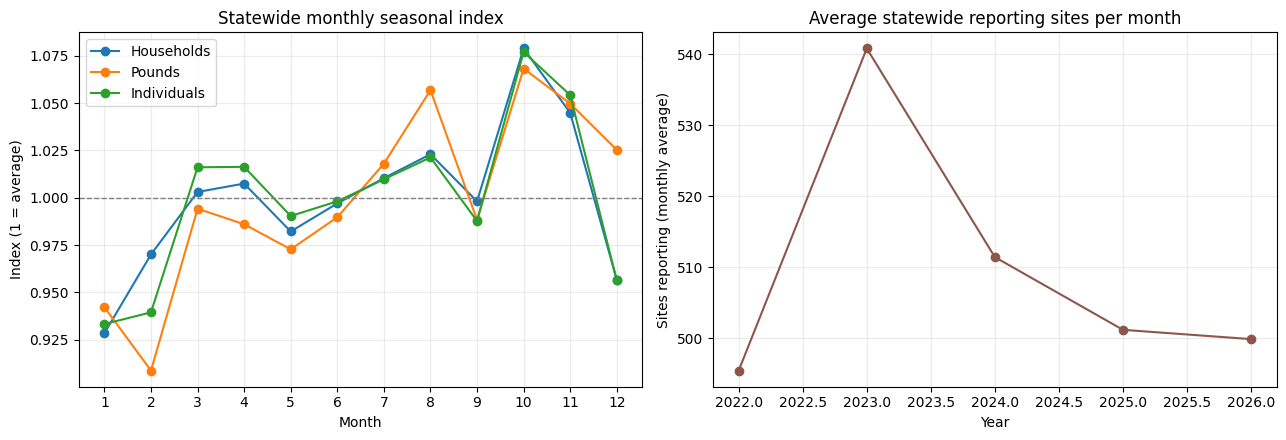

In [6]:
forecast_metrics = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]
state_month = panel.groupby(["year", "month"], as_index=False)[forecast_metrics + ["n_sites_reporting"]].sum()
seasonality = state_month.groupby("month")[forecast_metrics].mean()
seasonality = seasonality.div(seasonality.mean(axis=0), axis="columns")
seasonality.index.name = "calendar_month"
display(seasonality.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for metric in cfg.THREE_METRICS:
    axes[0].plot(seasonality.index, seasonality[metric], marker="o", label=metric.title())
axes[0].axhline(1, color="0.5", linestyle="--", linewidth=1)
axes[0].set(title="Statewide monthly seasonal index", xlabel="Month", ylabel="Index (1 = average)", xticks=range(1, 13))
axes[0].legend()

site_counts = state_month.groupby("year", as_index=False)["n_sites_reporting"].mean()
axes[1].plot(site_counts["year"], site_counts["n_sites_reporting"], marker="o", color="#8c564b")
axes[1].set(title="Average statewide reporting sites per month", xlabel="Year", ylabel="Sites reporting (monthly average)")
axes[1].grid(alpha=0.25)
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Run the leakage-safe backtests and forecast

The script compares seasonal naive, county August/July ratio, seasonal naive with drift, a ratio pooled toward the statewide median, and a per-reporting-site ratio. It selects separately by outcome using average county-level sMAPE over the three backtest years, while also reporting WAPE and MAE. The official competition score has not been confirmed, so sMAPE is a working selection metric—not a claim about the judges' metric.

In [7]:
import runpy

analysis_path = ROOT / "questions" / "q7_forecast_august" / "analysis.py"
runpy.run_path(str(analysis_path), run_name="__main__")

Q7 -- Backtest and forecast August 2026 activity
leakage_check passed: nothing at or after 202608
  -> outputs/tables/q7_backtest_predictions.csv  (8091 rows)
  -> outputs/tables/q7_backtest_scores.csv  (124 rows)
  -> outputs/tables/q7_method_selection.csv  (31 rows)
  -> outputs/tables/q7_forecasts.csv  (522 rows)
  -> outputs/tables/q7_uncertainty_calibration.csv  (6 rows)

Selected forecast methods:
     metric          selected_method
     adults pooled_august_july_ratio
   children pooled_august_july_ratio
 households pooled_august_july_ratio
individuals            age_group_sum
     pounds pooled_august_july_ratio
    seniors pooled_august_july_ratio

Lowest mean-fold sMAPE candidate per metric; final Individuals uses age sum:
     metric                   method  mean_fold_smape_pct  mean_fold_wape_pct
     adults pooled_august_july_ratio            18.373916           11.695221
   children pooled_august_july_ratio            20.896700           13.622498
 households pooled_aug

{'__name__': '__main__',
 '__doc__': '\nQ7 -- Backtest and forecast August 2026 county activity.\n\nRun from the repo root:\n    python questions/q7_forecast_august/analysis.py\n\nAll forecasts and backtests use the processed panel only. The leakage check is\ndeliberately run before any target selection; no August 2026 data is permitted.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/Users/uddam/Desktop/MinneMUDAC/questions/q7_forecast_august/analysis.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, exceptions, and other objects.\n\nNoteworthy: None is the `nil' object; Ellipsis represents `...' in slices.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__>,
  'abs': <function abs(x,

In [8]:
table_dir = ROOT / "outputs" / "tables"
forecasts = pd.read_csv(table_dir / "q7_forecasts.csv", dtype={"fips": "string"})
backtest_predictions = pd.read_csv(table_dir / "q7_backtest_predictions.csv", dtype={"fips": "string"})
backtest_scores = pd.read_csv(table_dir / "q7_backtest_scores.csv")
method_selection = pd.read_csv(table_dir / "q7_method_selection.csv")
uncertainty = pd.read_csv(table_dir / "q7_uncertainty_calibration.csv")

display(method_selection.loc[method_selection.selected_for_forecast].sort_values("metric").reset_index(drop=True))

,metric,method,mean_fold_smape_pct,worst_fold_smape_pct,mean_fold_wape_pct,mean_fold_mae,backtest_folds,selected_for_forecast
0,adults,pooled_august_july_ratio,18.373916,23.095578,11.695221,517.513931,3,True
1,children,pooled_august_july_ratio,20.896700,23.486510,13.622498,417.926498,3,True
2,households,pooled_august_july_ratio,16.248805,17.517064,11.732951,323.038015,3,True
3,individuals,age_group_sum,16.716753,19.736162,11.607475,978.713108,3,True
4,pounds,pooled_august_july_ratio,19.258030,22.296804,14.488714,21806.385327,3,True
5,seniors,pooled_august_july_ratio,18.813705,20.776245,13.039374,123.773978,3,True


## Backtest performance

The plot shows county-level sMAPE by backtest target. Lower is better. Compare fold-level performance as well as the average: there are only three backtest Augusts, so this is limited evidence, and a good average does not guarantee a good result in 2026.

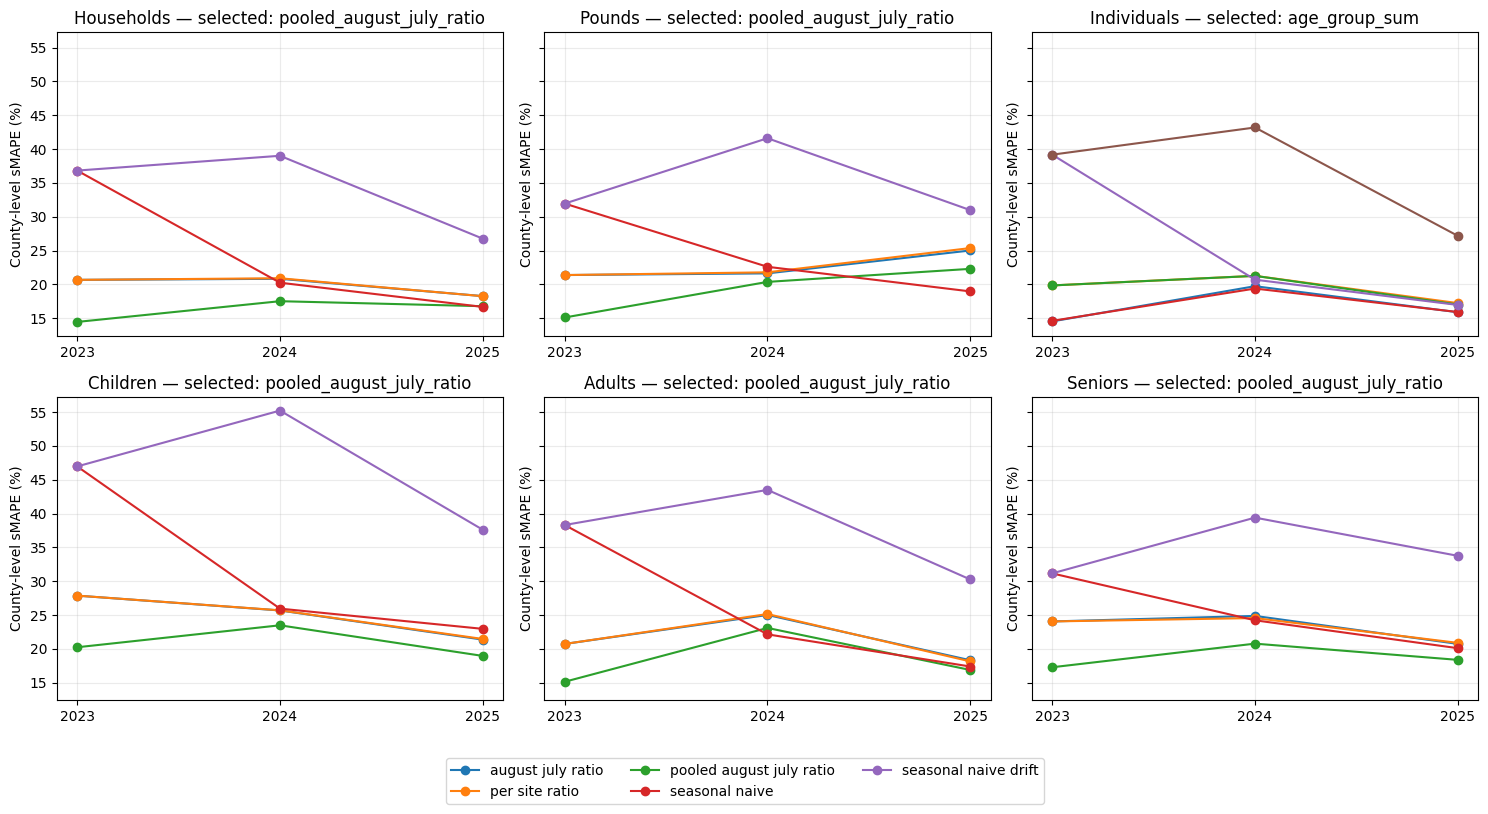

,metric,method,macro_smape_pct,wape_pct,mae
2,adults,pooled_august_july_ratio,18.37,11.70,517.51
1,adults,per_site_ratio,21.34,12.76,565.77
0,adults,august_july_ratio,21.36,12.98,575.40
3,adults,seasonal_naive,25.95,18.23,798.29
4,adults,seasonal_naive_drift,37.35,34.06,1513.35
7,children,pooled_august_july_ratio,20.90,13.62,417.93
5,children,august_july_ratio,24.97,15.45,472.64
6,children,per_site_ratio,25.01,15.20,465.31
8,children,seasonal_naive,31.96,19.53,597.38
9,children,seasonal_naive_drift,46.60,37.85,1173.28


In [9]:
score_folds = backtest_scores.loc[backtest_scores["target_year"].ne("ALL")].copy()
score_folds["target_year"] = score_folds["target_year"].astype(int)
metrics_to_plot = [*cfg.THREE_METRICS, *cfg.AGE_METRICS]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, metric in zip(axes.flat, metrics_to_plot):
    subset = score_folds.loc[score_folds.metric.eq(metric)]
    for method, group in subset.groupby("method"):
        ax.plot(group.target_year, group.macro_smape_pct, marker="o", label=method.replace("_", " "))
    selected = method_selection.loc[method_selection.metric.eq(metric) & method_selection.selected_for_forecast, "method"]
    ax.set_title(f"{metric.title()} — selected: {selected.iloc[0] if len(selected) else 'n/a'}")
    ax.set_xticks([2023, 2024, 2025])
    ax.set_ylabel("County-level sMAPE (%)")
    ax.grid(alpha=0.25)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

display(
    score_folds.groupby(["metric", "method"], as_index=False)[["macro_smape_pct", "wape_pct", "mae"]]
    .mean().sort_values(["metric", "macro_smape_pct"]).round(2)
)

### Rubric-aligned performance: county RMSE by scored outcome

The draft graduate rubric scores the five required forecast outcomes using county-level RMSE. This chart recomputes RMSE from each selected method's August 2023, 2024, and 2025 backtest predictions. Each panel has its own units and scale, so compare years within an outcome—not the heights across different outcomes. Lower RMSE is better.

In [ ]:
rubric_metrics = [cfg.M_VISITS, cfg.M_POUNDS, *cfg.AGE_METRICS]
selected_methods = method_selection.loc[
    method_selection.selected_for_forecast, ["metric", "method"]
]
selected_backtest = backtest_predictions.merge(
    selected_methods, on=["metric", "method"], how="inner", validate="m:1"
).dropna(subset=["actual", "prediction"])
selected_backtest = selected_backtest.loc[
    selected_backtest.metric.isin(rubric_metrics)
].copy()
selected_backtest["squared_error"] = (
    selected_backtest.prediction - selected_backtest.actual
) ** 2
rmse_by_fold = (
    selected_backtest.groupby(["metric", "target_year"], as_index=False)
    .agg(counties=("fips", "nunique"), mse=("squared_error", "mean"))
)
rmse_by_fold["rmse"] = np.sqrt(rmse_by_fold.mse)
rmse_by_fold["metric_label"] = rmse_by_fold.metric.map({
    cfg.M_VISITS: "Households (visits proxy)",
    cfg.M_POUNDS: "Pounds",
    "children": "Children",
    "adults": "Adults",
    "seniors": "Seniors",
})
display(rmse_by_fold[["metric_label", "target_year", "counties", "rmse"]]
        .sort_values(["metric_label", "target_year"]).round(1))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, metric in zip(axes.flat, rubric_metrics):
    subset = rmse_by_fold.loc[rmse_by_fold.metric.eq(metric)].sort_values("target_year")
    ax.plot(subset.target_year, subset.rmse, marker="o", linewidth=2, color="#2171b5")
    ax.set_title(subset.metric_label.iloc[0])
    ax.set_xticks([2023, 2024, 2025])
    ax.set_ylabel("County RMSE (outcome units)")
    ax.grid(alpha=0.25)
axes.flat[-1].set_visible(False)
fig.suptitle("Selected-model backtest RMSE by outcome", fontsize=15)
fig.text(0.5, 0.01,
         "Each point is RMSE across counties for one held-out August. Units differ by panel; compare years within each panel only.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()

## August 2026 forecast and empirical uncertainty range

The lower and upper columns are the 10th and 90th percentile empirical-error ranges from the selected method's backtests. They are **not calibrated guarantees**; only three target years are available. Wilkin County is included with blank estimates because it has no reporting history—zero activity would incorrectly imply observed absence of service.

,metric,counties,forecasted_counties,point_forecast,lower_80_sum,upper_80_sum,method
0,adults,87,86,403779.3,303102.7,495259.6,pooled_august_july_ratio
1,children,87,86,265935.3,185689.1,361166.4,pooled_august_july_ratio
2,households,87,86,243813.6,184281.8,280054.6,pooled_august_july_ratio
3,individuals,87,86,757214.9,583892.6,907738.0,age_group_sum
4,pounds,87,86,13503039.5,9896528.3,16156164.5,pooled_august_july_ratio
5,seniors,87,86,87500.3,65072.6,106083.9,pooled_august_july_ratio


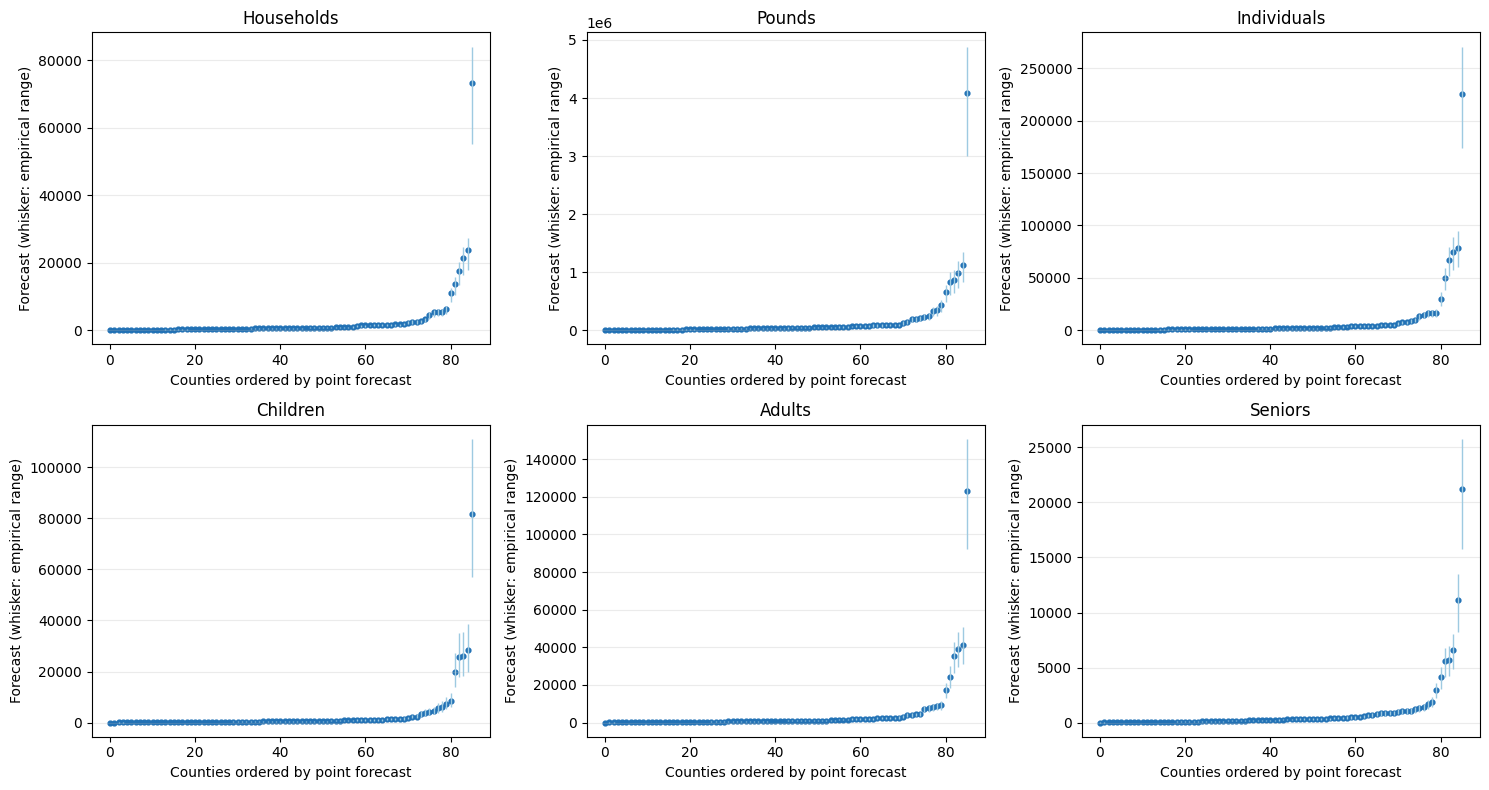

,fips,county_name,metric,forecast_status
498,27167,Wilkin,adults,no_reporting_history
499,27167,Wilkin,children,no_reporting_history
500,27167,Wilkin,households,no_reporting_history
501,27167,Wilkin,individuals,no_reporting_history
502,27167,Wilkin,pounds,no_reporting_history
503,27167,Wilkin,seniors,no_reporting_history


In [10]:
display(
    forecasts.groupby("metric", as_index=False).agg(
        counties=("fips", "nunique"),
        forecasted_counties=("prediction", "count"),
        point_forecast=("prediction", "sum"),
        lower_80_sum=("lower_80", "sum"),
        upper_80_sum=("upper_80", "sum"),
        method=("selected_method", "first"),
    ).round(1)
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.flat, metrics_to_plot):
    subset = forecasts.loc[forecasts.metric.eq(metric) & forecasts.prediction.notna()].sort_values("prediction")
    x = np.arange(len(subset))
    ax.vlines(x, subset.lower_80, subset.upper_80, color="#9ecae1", linewidth=1)
    ax.scatter(x, subset.prediction, s=12, color="#2171b5")
    ax.set_title(metric.title())
    ax.set_xlabel("Counties ordered by point forecast")
    ax.set_ylabel("Forecast (whisker: empirical range)")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

display(forecasts.loc[forecasts.forecast_status.eq("no_reporting_history"), ["fips", "county_name", "metric", "forecast_status"]])

## Graduate age-group checks

Individuals is derived county-by-county as children + adults + seniors. The table also flags forecasts whose age share falls outside that county's historical monthly range; these are reviewed rather than silently clipped. The range flag is a diagnostic, not a hard modeling constraint.

In [11]:
age_forecasts = forecasts.loc[forecasts.metric.isin(cfg.AGE_METRICS)].copy()
age_share_flags = age_forecasts.loc[
    age_forecasts.age_share_within_historical_range.eq(False),
    ["fips", "county_name", "metric", "prediction", "age_share_forecast",
     "age_share_historical_min", "age_share_historical_max"],
].sort_values(["metric", "county_name"])
display(age_share_flags.round(3))

wide_forecast = forecasts.pivot(index="fips", columns="metric", values="prediction")
age_sum = wide_forecast[cfg.AGE_METRICS].sum(axis=1, min_count=3)
if not np.allclose(wide_forecast[cfg.M_INDIVIDUALS].dropna(), age_sum.dropna()):
    raise ValueError("Derived Individuals does not reconcile to the age-group forecasts")
print("Age-group sum check passed for every county with a forecast.")
print(f"Counties with at least one age-share range flag: {age_share_flags.fips.nunique()}")

,fips,county_name,metric,prediction,age_share_forecast,age_share_historical_min,age_share_historical_max
288,27097,Morrison,adults,916.344,0.584,0.525,0.580
468,27157,Wabasha,adults,2182.341,0.579,0.477,0.579
91,27031,Cook,children,114.871,0.212,0.237,0.403
223,27075,Lake,children,93.015,0.147,0.167,0.264
487,27163,Washington,children,26233.290,0.333,0.336,0.415
17,27005,Becker,seniors,261.919,0.156,0.113,0.152
227,27075,Lake,seniors,201.741,0.319,0.131,0.304


Age-group sum check passed for every county with a forecast.
Counties with at least one age-share range flag: 6


## Interpretation and limitations

- Reported activity reflects both service demand and which organizations submitted data; July 2026's reporting-site count may still be incomplete.
- County-level data rolls up Hennepin and Ramsey to whole counties. It cannot produce split forecasts from this panel.
- Wilkin has no reporting history, so no statistical forecast is created for it.
- The selected pooled ratio is a simple baseline that won these three backtest folds; do not present this as proof it will be most accurate in August 2026.
- Confirm the competition score, county geography, July finality and Wilkin treatment with organizers. A person other than the model author must complete the repository-wide leakage audit before submission.

The saved submission-oriented table is `outputs/tables/q7_forecasts.csv`; detailed backtests and method comparisons are in the other `q7_*.csv` tables. Re-run this notebook after running the cells top to bottom to refresh all results.